## Importing necessary libraries

In [281]:
import torch
import numpy as np
import sklearn
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


## Printing first 10 images to check the dataset alongwith their labels

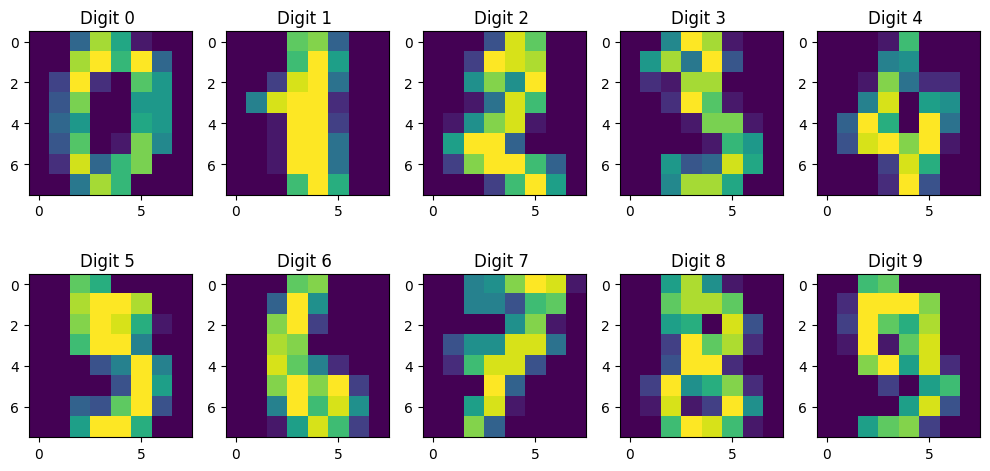

In [282]:
digits=load_digits()
X=digits.images
y=digits.target

fig, axes=plt.subplots(nrows=2, ncols=5, figsize=(10,5))

for i, ax in enumerate(axes.flat):
  ax.imshow(X[i], cmap='viridis')

  ax.set_title(f"Digit {y[i]} ")

plt.tight_layout()
plt.show()

## Dimensions of the image

In [283]:
print("Pixels per image:", X[0].size)
print("Full dataset shape:", X.shape)

Pixels per image: 64
Full dataset shape: (1797, 8, 8)


## Counting unique value counts per label

In [284]:
labels, counts = np.unique(y, return_counts=True)

for label, count in zip(labels, counts):
  print(f"Digit {label}: {count} images")

print("Total images:", len(y))

Digit 0: 178 images
Digit 1: 182 images
Digit 2: 177 images
Digit 3: 183 images
Digit 4: 181 images
Digit 5: 182 images
Digit 6: 181 images
Digit 7: 179 images
Digit 8: 174 images
Digit 9: 180 images
Total images: 1797


## Splitting the dataset into training and temporary sets


In [285]:
X_train, X_temp, y_train, y_temp= train_test_split(X, y, stratify=y, random_state=42, test_size=0.3)

## Splitting the temporary dataset into validation and testing ratio as 50:50

In [286]:
X_val, X_test, y_val, y_test=train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

## Converting images to PyTorch tensors

In [287]:
X_train=torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)
X_val=torch.tensor(X_val, dtype=torch.float32).unsqueeze(1)
X_test=torch.tensor(X_test, dtype=torch.float32).unsqueeze(1)

y_train=torch.tensor(y_train, dtype=torch.long)
y_val=torch.tensor(y_val, dtype=torch.long)
y_test=torch.tensor(y_test, dtype=torch.long)

## Normalizing images into grayscale

In [288]:
X_train /=16.0
X_val /=16.0
X_test /=16.0

## Making a CNN: Train a convolutional classifier that accepts [batch, 1, 8, 8] and outputs ten class scores.

In [289]:
train_dataset=TensorDataset(X_train, y_train)
val_dataset=TensorDataset(X_val, y_val)
test_dataset=TensorDataset(X_test, y_test)

train_loader=DataLoader(train_dataset, shuffle=True, batch_size=32)
val_loader=DataLoader(val_dataset, shuffle=False, batch_size=32)
test_loader=DataLoader(test_dataset, shuffle=False, batch_size=32)

## Defining Model here

In [290]:
class DigitCNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv=nn.Conv2d(
        in_channels=1,
        out_channels=8,
        kernel_size=3,
        padding=1
    )

    self.relu=nn.ReLU()
    self.pooling=nn.MaxPool2d(kernel_size=2)
    self.flatten=nn.Flatten()
    self.fc=nn.Linear(8*4*4,10)

  def forward(self, x):
    x=self.conv(x)
    x=self.relu(x)
    x=self.pooling(x)
    x=self.flatten(x)
    x=self.fc(x)

    return x

In [291]:
model=DigitCNN()

## Defining loss function and optimizer

In [292]:
criterion=nn.CrossEntropyLoss()

In [293]:
optimizer=torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

## Training Loop

In [294]:
def train_one_epoch(model, loader, criterion, optimizer):
  model.train()
  total_loss=0
  correct=0
  total=0

  for images, labels in loader:
    optimizer.zero_grad()

    outputs=model(images)
    loss_factor=criterion(outputs, labels)

    loss_factor.backward() # go back
    optimizer.step() # optimizer adjusts weight
    predictions=outputs.argmax(dim=1)

    correct+= (predictions==labels).sum().item()
    total+=labels.size(0)
    total_loss+=loss_factor.item()

  average_loss=total_loss/len(loader)
  accuracy=correct/total

  return average_loss, accuracy


## 20 epochs and training model on the data for a loss threshold of 0.3

In [295]:
epochs=20

for i in range(epochs):
  train_loss, train_acc=train_one_epoch(
      model, train_loader, criterion, optimizer
  )

  print(f"Epoch: {i+1}")
  print(f"Accuracy: {train_acc}")
  print(f"Training Loss: {train_loss}")

  if(train_loss <= 0.3):
    print("Target loss has reached. So early stopping!")
    break

Epoch: 1
Accuracy: 0.6205250596658711
Training Loss: 1.463010920584202
Epoch: 2
Accuracy: 0.9148766905330151
Training Loss: 0.35311305411159993
Epoch: 3
Accuracy: 0.9371519490851233
Training Loss: 0.2094892947934568
Target loss has reached. So early stopping!


## Evaluating the model function

In [296]:
def evaluate_model(model, loader, criterion):
  model.eval()

  correct=0
  total_loss=0
  total=0

  with torch.no_grad():
    for images, labels in loader:
      outputs=model(images)
      loss=criterion(outputs, labels)
      predictions=outputs.argmax(dim=1)

      correct+=(predictions==labels).sum().item()
      total+=labels.size(0)
      total_loss+=loss.item()

  average_loss=total_loss/len(loader)
  accuracy=correct/total

  return average_loss, accuracy

## Evaluating Validation dataset

In [297]:
val_loss, val_accuracy=evaluate_model(
    model, val_loader,criterion
)
print(f"Validation Data accuracy is {val_accuracy}")
print(f"Validation Data Loss is {val_loss}")

Validation Data accuracy is 0.9296296296296296
Validation Data Loss is 0.2359106946322653


## Evaluating the Tests Dataset

In [298]:
test_loss, test_accuracy=evaluate_model(
    model, test_loader,criterion
)
print(f"Tests Set Data accuracy is {test_accuracy}")
print(f"Test Set Data Loss is {test_loss}")

Tests Set Data accuracy is 0.9555555555555556
Test Set Data Loss is 0.1611286492811309


## Verify the CNN architecture

In [299]:
images, labels = next(iter(test_loader))

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Predictions:", outputs.argmax(dim=1))

Input shape: torch.Size([32, 1, 8, 8])
Output shape: torch.Size([32, 10])
Predictions: tensor([6, 1, 8, 1, 3, 7, 6, 6, 8, 0, 7, 8, 9, 3, 5, 5, 7, 8, 3, 9, 6, 3, 8, 6,
        6, 2, 2, 8, 8, 6, 7, 0])


## VIsualizing all metrics through bars for all datasets

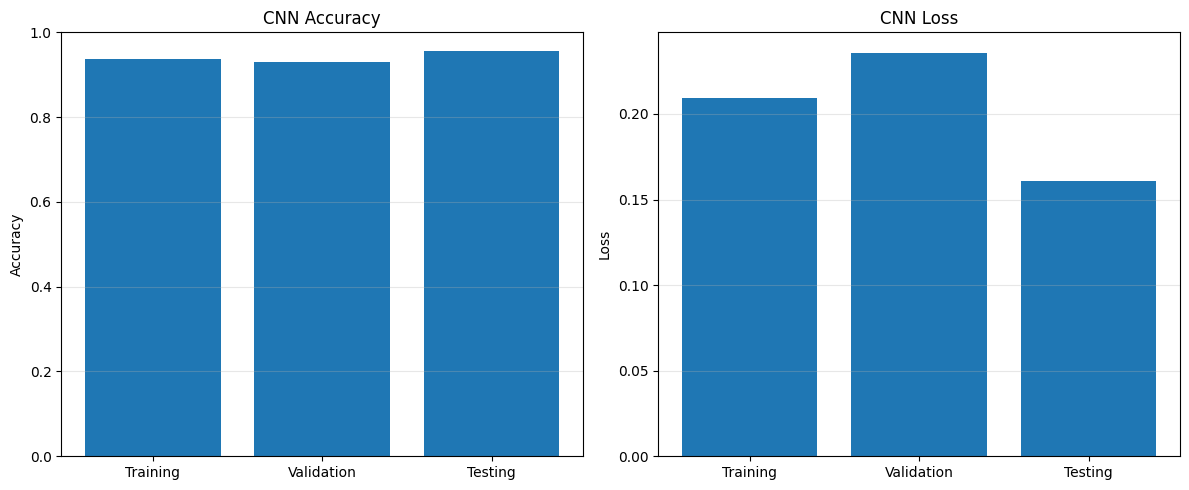

In [300]:
import matplotlib.pyplot as plt

# CNN results
accuracy = [
    train_acc,
    val_accuracy,
    test_accuracy
]

loss = [
    train_loss,
    val_loss,
    test_loss
]

datasets = ["Training", "Validation", "Testing"]

# Create two charts in one figure
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Accuracy chart
axes[0].bar(datasets, accuracy)
axes[0].set_title("CNN Accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].grid(axis="y", alpha=0.3)

# Loss chart
axes[1].bar(datasets, loss)
axes[1].set_title("CNN Loss")
axes[1].set_ylabel("Loss")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Saving the CNN model

In [301]:
torch.save(model.state_dict(), 'digitCNN.pth')

## Vision Transformer

## Creating patches for each image

In [302]:
def create_patches(images):
  patches=images.unfold(2,2,2).unfold(3,2,2)
  patches=patches.squeeze(1)
  patches=patches.reshape(images.shape[0], 16, 4)
  return patches

## Applying patch function per batch

In [303]:
images, labels=next(iter(train_loader))
patches=create_patches(images)


print(f"Original Images: {images.shape}")
print(f"Patches Dimensions: {patches.shape}")


Original Images: torch.Size([32, 1, 8, 8])
Patches Dimensions: torch.Size([32, 16, 4])


## Creating Patch Embedding for 32 dimensions

In [304]:
patch_embedding = nn.Linear(4, 32)
embedded_patches = patch_embedding(patches)

print(f"Patches Dimensions: {patches.shape}")

print(f"Embedded Patches: {embedded_patches.shape}")

print(f"Embedding shape: {embedded_patches[0][0].shape}")

Patches Dimensions: torch.Size([32, 16, 4])
Embedded Patches: torch.Size([32, 16, 32])
Embedding shape: torch.Size([32])


## Telling the model the position of each embedding

In [305]:
patch_embedding_position=nn.Parameter(
    torch.randn(1, 16, 32)
)

positioned_patches = embedded_patches + patch_embedding_position

print("Embedded:", embedded_patches.shape)
print("Position:", patch_embedding_position.shape)
print("After adding:", positioned_patches.shape)

Embedded: torch.Size([32, 16, 32])
Position: torch.Size([1, 16, 32])
After adding: torch.Size([32, 16, 32])


## Creating a Transformer layer for self attention

In [306]:
transformer_layer=nn.TransformerEncoderLayer(
    d_model=32, # Each patch is represented by 32 numbers.
    nhead=4, # Use 4 attention heads to examine relationships.
    dim_feedforward=64, # The internal feedforward network has 64 hidden dimensions.
    batch_first=True
)

In [307]:
transformed_patches = transformer_layer(positioned_patches)

print("Before Transformer:", positioned_patches.shape)
print("After Transformer:", transformed_patches.shape)

Before Transformer: torch.Size([32, 16, 32])
After Transformer: torch.Size([32, 16, 32])


## Combining all the patches and their information

## Implementing mean pooling

In [308]:
image_representation = transformed_patches.mean(dim=1)

print("Before pooling:", transformed_patches.shape)
print("After pooling:", image_representation.shape)

Before pooling: torch.Size([32, 16, 32])
After pooling: torch.Size([32, 32])


## Using a Linear model with 32 input features instead of 128

In [309]:
classifier=nn.Linear(32, 10)

In [310]:
outputs=classifier(image_representation)
print("Image representation:", image_representation.shape)
print("Classification output:", outputs.shape)

Image representation: torch.Size([32, 32])
Classification output: torch.Size([32, 10])


## Creating a DigitViT class for Visusal Transformer

In [311]:
class DigitViT(nn.Module):
  def __init__(self):
    super().__init__()

    self.patch_embedding=nn.Linear(4, 32)
    self.pos_embedding = nn.Parameter(
            torch.randn(1, 16, 32)
        )
    self.transformer = nn.TransformerEncoderLayer(
            d_model=32,
            nhead=4,
            dim_feedforward=64,
            batch_first=True
        )

    self.classifier = nn.Linear(32, 10)

  def forward(self, x):
    x = x.unfold(2, 2, 2).unfold(3, 2, 2)

    x = x.squeeze(1)
    x = x.reshape(x.shape[0], 16, 4)

    x = self.patch_embedding(x)
    x = x + self.pos_embedding

    x = self.transformer(x)
    x = x.mean(dim=1)

        # STEP 6: Predict 10 digit scores
    x = self.classifier(x)
    return x


In [312]:
vit_model=DigitViT()
images, labels= next(iter(train_loader))
outputs=vit_model(images)
print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 1, 8, 8])
Output shape: torch.Size([32, 10])


## Training the model

In [313]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    vit_model.parameters(),
    lr=0.001
)

## Train all epoch

In [314]:

epochs = 20

for epoch in range(epochs):

    train_loss, train_accuracy = train_one_epoch(
        vit_model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_accuracy = evaluate_model(
        vit_model,
        val_loader,
        criterion
    )

    print(f"Epoch [{epoch+1}/{epochs}]")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print("-" * 40)


Epoch [1/20]
Training Loss: 2.3205
Training Accuracy: 0.1090
Validation Loss: 2.3013
Validation Accuracy: 0.1000
----------------------------------------
Epoch [2/20]
Training Loss: 2.2897
Training Accuracy: 0.1193
Validation Loss: 2.2713
Validation Accuracy: 0.1926
----------------------------------------
Epoch [3/20]
Training Loss: 2.2248
Training Accuracy: 0.2418
Validation Loss: 2.1260
Validation Accuracy: 0.3000
----------------------------------------
Epoch [4/20]
Training Loss: 1.8469
Training Accuracy: 0.4566
Validation Loss: 1.5179
Validation Accuracy: 0.5296
----------------------------------------
Epoch [5/20]
Training Loss: 1.3576
Training Accuracy: 0.6078
Validation Loss: 1.2204
Validation Accuracy: 0.6333
----------------------------------------
Epoch [6/20]
Training Loss: 1.0977
Training Accuracy: 0.7017
Validation Loss: 1.0685
Validation Accuracy: 0.7000
----------------------------------------
Epoch [7/20]
Training Loss: 0.9073
Training Accuracy: 0.7383
Validation Loss

## Evaluate on Validation Data

In [315]:
val_loss, val_accuracy = evaluate_model(
    vit_model,
    val_loader,
    criterion
)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)

Validation Loss: 0.3909533272186915
Validation Accuracy: 0.8666666666666667


## Evaluate on Test dataset

In [316]:
test_loss, test_accuracy = evaluate_model(
    vit_model,
    test_loader,
    criterion
)

print("ViT Test Loss:", test_loss)
print("ViT Test Accuracy:", test_accuracy)
print("ViT Test Accuracy (%):", test_accuracy * 100)

ViT Test Loss: 0.30360932648181915
ViT Test Accuracy: 0.9
ViT Test Accuracy (%): 90.0


## Visualizing the Metrics Accuray and Loss for all Datasets

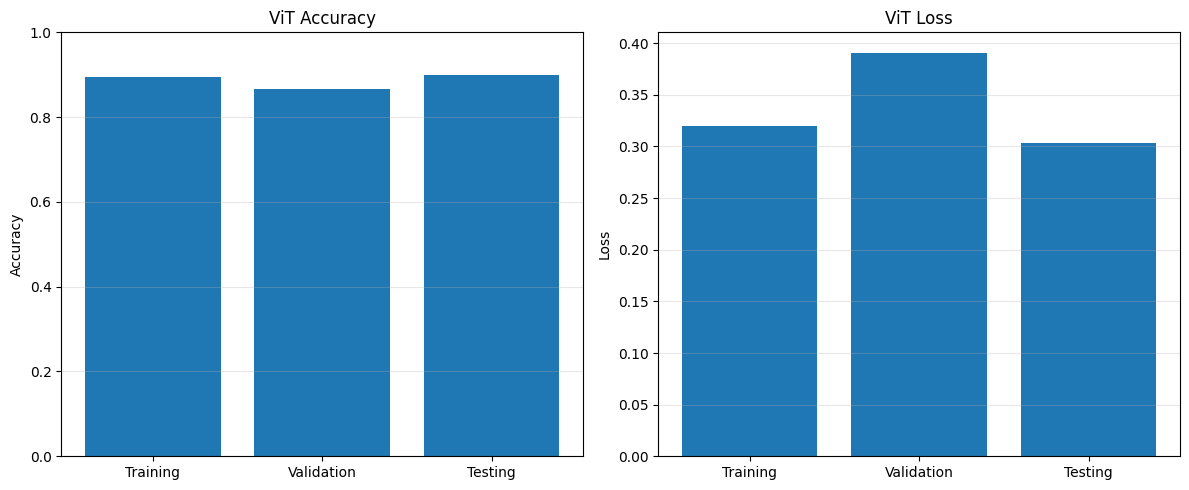

In [317]:
import matplotlib.pyplot as plt

# CNN results
accuracy = [
    train_accuracy,
    val_accuracy,
    test_accuracy
]

loss = [
    train_loss,
    val_loss,
    test_loss
]

datasets = ["Training", "Validation", "Testing"]

# Create two charts in one figure
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Accuracy chart
axes[0].bar(datasets, accuracy)
axes[0].set_title("ViT Accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].grid(axis="y", alpha=0.3)

# Loss chart
axes[1].bar(datasets, loss)
axes[1].set_title("ViT Loss")
axes[1].set_ylabel("Loss")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Testing model on a random image

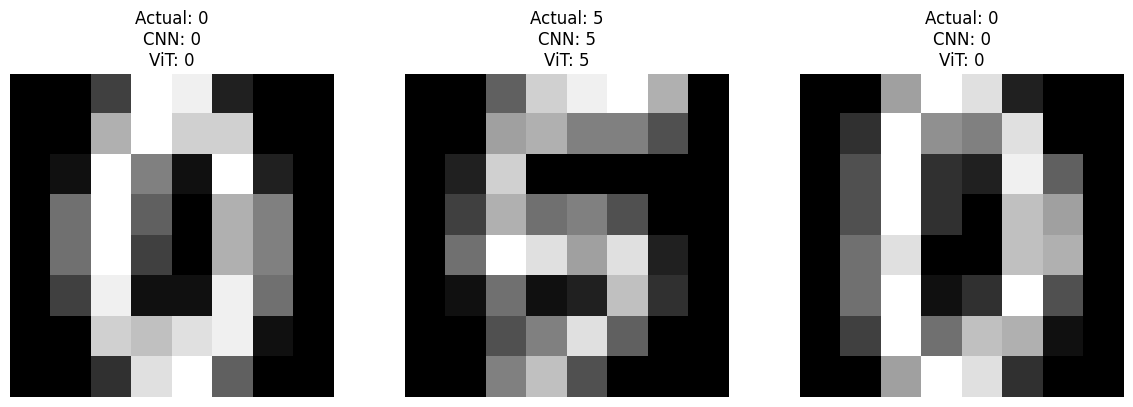

In [318]:
random_indexes = random.sample(range(len(X_test)), 3)

images = torch.stack([X_test[i] for i in random_indexes])
actual_labels = [y_test[i].item() for i in random_indexes]

model.eval()
vit_model.eval()

with torch.no_grad():
    cnn_outputs = model(images)
    vit_outputs = vit_model(images)

    cnn_predictions = cnn_outputs.argmax(dim=1).tolist()
    vit_predictions = vit_outputs.argmax(dim=1).tolist()
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for i, ax in enumerate(axes):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(
        f"Actual: {actual_labels[i]}\n"
        f"CNN: {cnn_predictions[i]}\n"
        f"ViT: {vit_predictions[i]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


## Saving the DigitViT model

In [319]:
torch.save(vit_model.state_dict(), "digitViT.pth")

## Make a prediction function

In [320]:
def get_predictions(model, loader):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return all_labels, all_predictions

## Evaluating CNN and Digit ViT

In [321]:

cnn_labels, cnn_predictions = get_predictions(
    model, test_loader
)

vit_labels, vit_predictions = get_predictions(
    vit_model, test_loader
)

print("CNN Accuracy:", accuracy_score(cnn_labels, cnn_predictions))
print("CNN Macro F1:", f1_score(cnn_labels, cnn_predictions, average="macro"))

print("\nViT Accuracy:", accuracy_score(vit_labels, vit_predictions))
print("ViT Macro F1:", f1_score(vit_labels, vit_predictions, average="macro"))

CNN Accuracy: 0.9555555555555556
CNN Macro F1: 0.9556179494858739

ViT Accuracy: 0.9
ViT Macro F1: 0.8989502169983368


## Setting up a baseline model

In [322]:
majority_class = torch.bincount(y_train).argmax().item()

baseline_predictions = [majority_class] * len(y_test)

baseline_accuracy = accuracy_score(
    y_test.numpy(),
    baseline_predictions
)

print("Majority class:", majority_class)
print("Baseline accuracy:", baseline_accuracy)

Majority class: 3
Baseline accuracy: 0.1037037037037037


## Plotting a confusion matrix

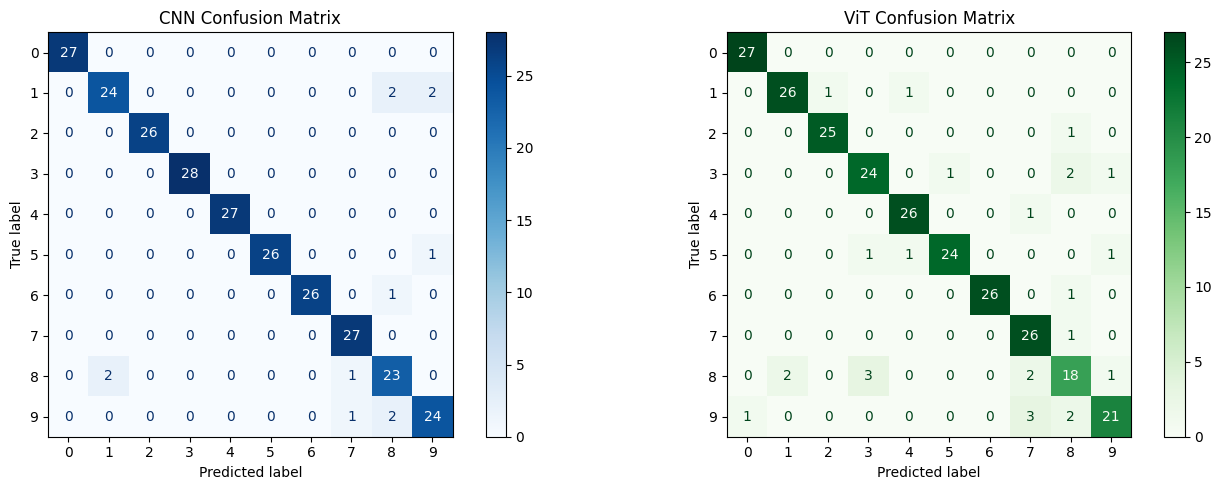

In [323]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    cnn_labels,
    cnn_predictions,
    ax=axes[0],
    cmap="Blues"
)

axes[0].set_title("CNN Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    vit_labels,
    vit_predictions,
    ax=axes[1],
    cmap="Greens"
)

axes[1].set_title("ViT Confusion Matrix")

plt.tight_layout()
plt.show()